In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
%pip install seaborn
import seaborn as sns

In [2]:
# Cargar archivo csv
df = pd.read_csv("Fitness_Classification.csv", encoding="utf-8")
df

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,NaN,2.37,3.97,no,F,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,F,1
2,46,192,103,61.4,116.4,NaN,8.20,2.03,0,F,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,M,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,yes,F,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,NaN,1.54,3.25,1,M,1
1996,61,186,74,51.4,123.8,9.4,8.63,3.15,no,M,1
1997,77,198,89,76.7,103.6,8.3,1.98,3.36,yes,M,0
1998,62,190,63,80.7,115.9,6.7,9.21,2.39,1,F,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                2000 non-null   int64  
 1   height_cm          2000 non-null   int64  
 2   weight_kg          2000 non-null   int64  
 3   heart_rate         2000 non-null   float64
 4   blood_pressure     2000 non-null   float64
 5   sleep_hours        1840 non-null   float64
 6   nutrition_quality  2000 non-null   float64
 7   activity_index     2000 non-null   float64
 8   smokes             2000 non-null   str    
 9   gender             2000 non-null   str    
 10  is_fit             2000 non-null   int64  
dtypes: float64(5), int64(4), str(2)
memory usage: 156.3 KB


In [4]:
print("Valores únicos en smokes:", df['smokes'].unique())
print("Valores únicos en gender:", df['gender'].unique())

Valores únicos en smokes: <StringArray>
['no', '0', 'yes', '1']
Length: 4, dtype: str
Valores únicos en gender: <StringArray>
['F', 'M']
Length: 2, dtype: str


In [5]:
df.replace({
    "smokes": {"no": 0, "0": 0, "yes": 1, "1": 1},
    "gender": {"F": 0, "M": 1}
}, inplace=True)

df['smokes'] = pd.to_numeric(df['smokes'])
df['gender'] = pd.to_numeric(df['gender'])
df

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,NaN,2.37,3.97,0,0,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,0,1
2,46,192,103,61.4,116.4,NaN,8.20,2.03,0,0,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,1,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,NaN,1.54,3.25,1,1,1
1996,61,186,74,51.4,123.8,9.4,8.63,3.15,0,1,1
1997,77,198,89,76.7,103.6,8.3,1.98,3.36,1,1,0
1998,62,190,63,80.7,115.9,6.7,9.21,2.39,1,0,0


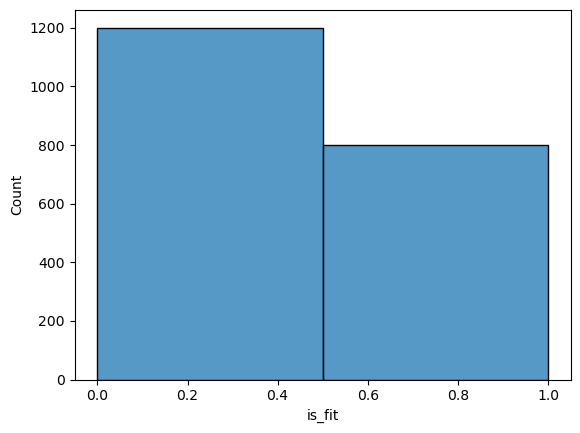

In [6]:
histo = sns.histplot(df['is_fit'], bins=2)

In [7]:
df.isnull().values.any()

np.True_

<Axes: >

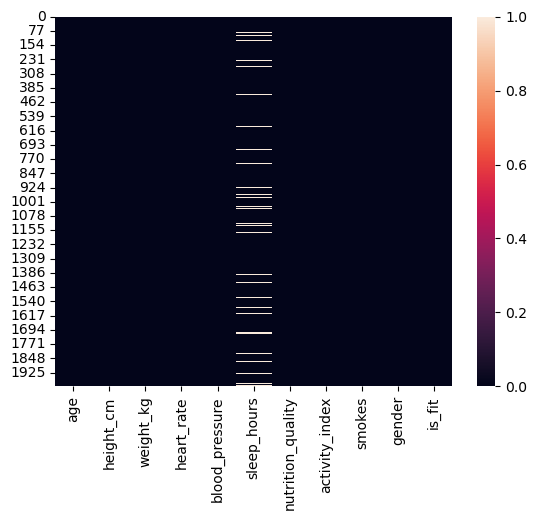

In [8]:
sns.heatmap(df.isnull())

In [9]:
df.isnull().sum(axis=0)

age                    0
height_cm              0
weight_kg              0
heart_rate             0
blood_pressure         0
sleep_hours          160
nutrition_quality      0
activity_index         0
smokes                 0
gender                 0
is_fit                 0
dtype: int64

In [10]:
from sklearn.impute import KNNImputer

impKNN = KNNImputer(n_neighbors=10)
fitness = pd.DataFrame(impKNN.fit_transform(df), columns=df.columns)

for col in ['age', 'height_cm', 'weight_kg', 'smokes', 'gender', 'is_fit']:
    fitness[col] = fitness[col].round().astype(int)

fitness

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,7.76,2.37,3.97,0,0,1
1,69,186,95,60.8,114.8,7.50,8.77,3.19,0,0,1
2,46,192,103,61.4,116.4,6.70,8.20,2.03,0,0,0
3,32,189,83,60.2,130.1,7.00,6.18,3.68,0,1,1
4,60,175,99,58.1,115.8,8.00,9.95,4.83,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,7.85,1.54,3.25,1,1,1
1996,61,186,74,51.4,123.8,9.40,8.63,3.15,0,1,1
1997,77,198,89,76.7,103.6,8.30,1.98,3.36,1,1,0
1998,62,190,63,80.7,115.9,6.70,9.21,2.39,1,0,0


In [11]:
fitness.isnull().sum(axis=0)

age                  0
height_cm            0
weight_kg            0
heart_rate           0
blood_pressure       0
sleep_hours          0
nutrition_quality    0
activity_index       0
smokes               0
gender               0
is_fit               0
dtype: int64

In [12]:
fitness.to_csv('Fitness_Classification_Limpio.csv', index=False)

In [14]:
from sklearn.model_selection import train_test_split

X = fitness.drop(columns='is_fit')
y = fitness['is_fit']
X

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender
0,56,152,65,69.6,117.0,7.76,2.37,3.97,0,0
1,69,186,95,60.8,114.8,7.50,8.77,3.19,0,0
2,46,192,103,61.4,116.4,6.70,8.20,2.03,0,0
3,32,189,83,60.2,130.1,7.00,6.18,3.68,0,1
4,60,175,99,58.1,115.8,8.00,9.95,4.83,1,0
...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,7.85,1.54,3.25,1,1
1996,61,186,74,51.4,123.8,9.40,8.63,3.15,0,1
1997,77,198,89,76.7,103.6,8.30,1.98,3.36,1,1
1998,62,190,63,80.7,115.9,6.70,9.21,2.39,1,0


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=6)

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_dist = {"max_depth": range(2, 7), 
              "max_features": range(1, 11),
              "min_samples_leaf": [25, 50, 100], 
              "criterion": ["gini", "entropy"]}

grid_search = GridSearchCV(estimator=DecisionTreeClassifier(random_state=6),
                           param_grid=param_dist, cv=5)

grid_search.fit(X_train, y_train)
grid_search.best_params_

{'criterion': 'entropy',
 'max_depth': 4,
 'max_features': 9,
 'min_samples_leaf': 25}

In [17]:
grid_search.best_score_

np.float64(0.75)

In [18]:
dtree = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    max_features=9,
    min_samples_leaf=25,
    random_state=6
)
dtree

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",25
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",6
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [19]:
dtree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",25
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",6
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [20]:
dtree.score(X_train, y_train)

0.7728571428571429

In [21]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

predictions = dtree.predict(X_test)
accuray_dt = accuracy_score(y_test, predictions)
f1_dt = f1_score(y_test, predictions)

print(f"Exactitud: {accuray_dt:0.2f}")

Exactitud: 0.71


In [22]:
print(confusion_matrix(y_test, predictions))

[[275  85]
 [ 89 151]]


Text(113.9222222222222, 0.5, 'Clasificación correcta:')

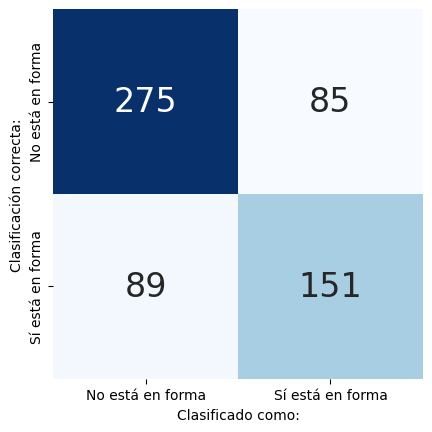

In [23]:
ydt_predicted = dtree.predict(X_test) > 0.5
mat_dt = confusion_matrix(y_test, ydt_predicted)
labels = ['No está en forma', 'Sí está en forma']

sns.heatmap(mat_dt, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=labels, yticklabels=labels, annot_kws={"size": 24})

sns.set(font_scale=1.3)
plt.xlabel('Clasificado como:')
plt.ylabel('Clasificación correcta:')

In [24]:
features = list(X)
features

['age',
 'height_cm',
 'weight_kg',
 'heart_rate',
 'blood_pressure',
 'sleep_hours',
 'nutrition_quality',
 'activity_index',
 'smokes',
 'gender']

In [25]:
target = ['No', 'Sí']

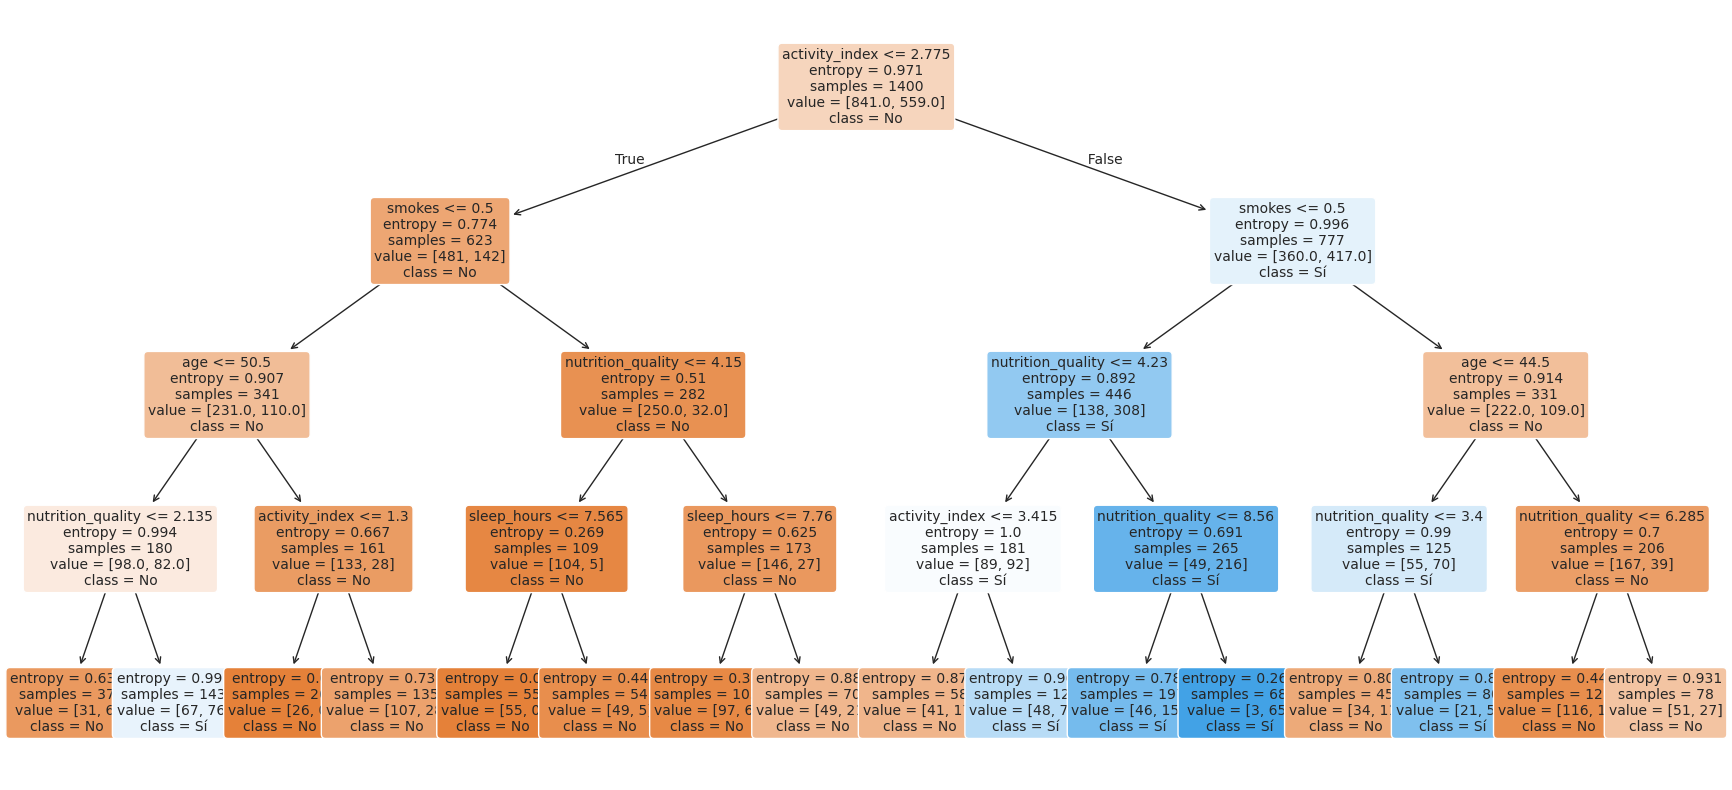

In [26]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))
plot_tree(dtree, feature_names=features, class_names=target, filled=True, rounded=True, fontsize=10)
plt.show()